In [1]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_vehicle_dataset():
    tarball_path = Path("datasets/vehicle.tgz")

    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url= "https://github.com/brightgoddaycode/data/raw/main/vehicle-dataset/vehicle.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as vehicle_tarball:
            vehicle_tarball.extractall(path="datasets/vehicle", filter="data")

    return pd.read_csv(Path("datasets/vehicle/car data.csv"))
vehicle_full = load_vehicle_dataset()
vehicle_full.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
print(vehicle_full["Car_Name"].value_counts())
print(vehicle_full["Fuel_Type"].value_counts())
print(vehicle_full["Seller_Type"].value_counts())
print(vehicle_full["Transmission"].value_counts())

Car_Name
city                  26
corolla altis         16
verna                 14
fortuner              11
brio                  10
                      ..
Honda Activa 125       1
Hero Hunk              1
Hero  Ignitor Disc     1
Hero  CBZ Xtreme       1
Bajaj  ct 100          1
Name: count, Length: 98, dtype: int64
Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64
Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64
Transmission
Manual       261
Automatic     40
Name: count, dtype: int64


In [3]:
vehicle_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [4]:
vehicle_full.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


All right, from what I can see there are no missing values, so there is no need for a Imputer, but we will stil add it for production whatever... Also, the selling price is in some unit something. It is measured in Lakhs of Indian Rupees (INR).
1 Lakh = 100,000 INR

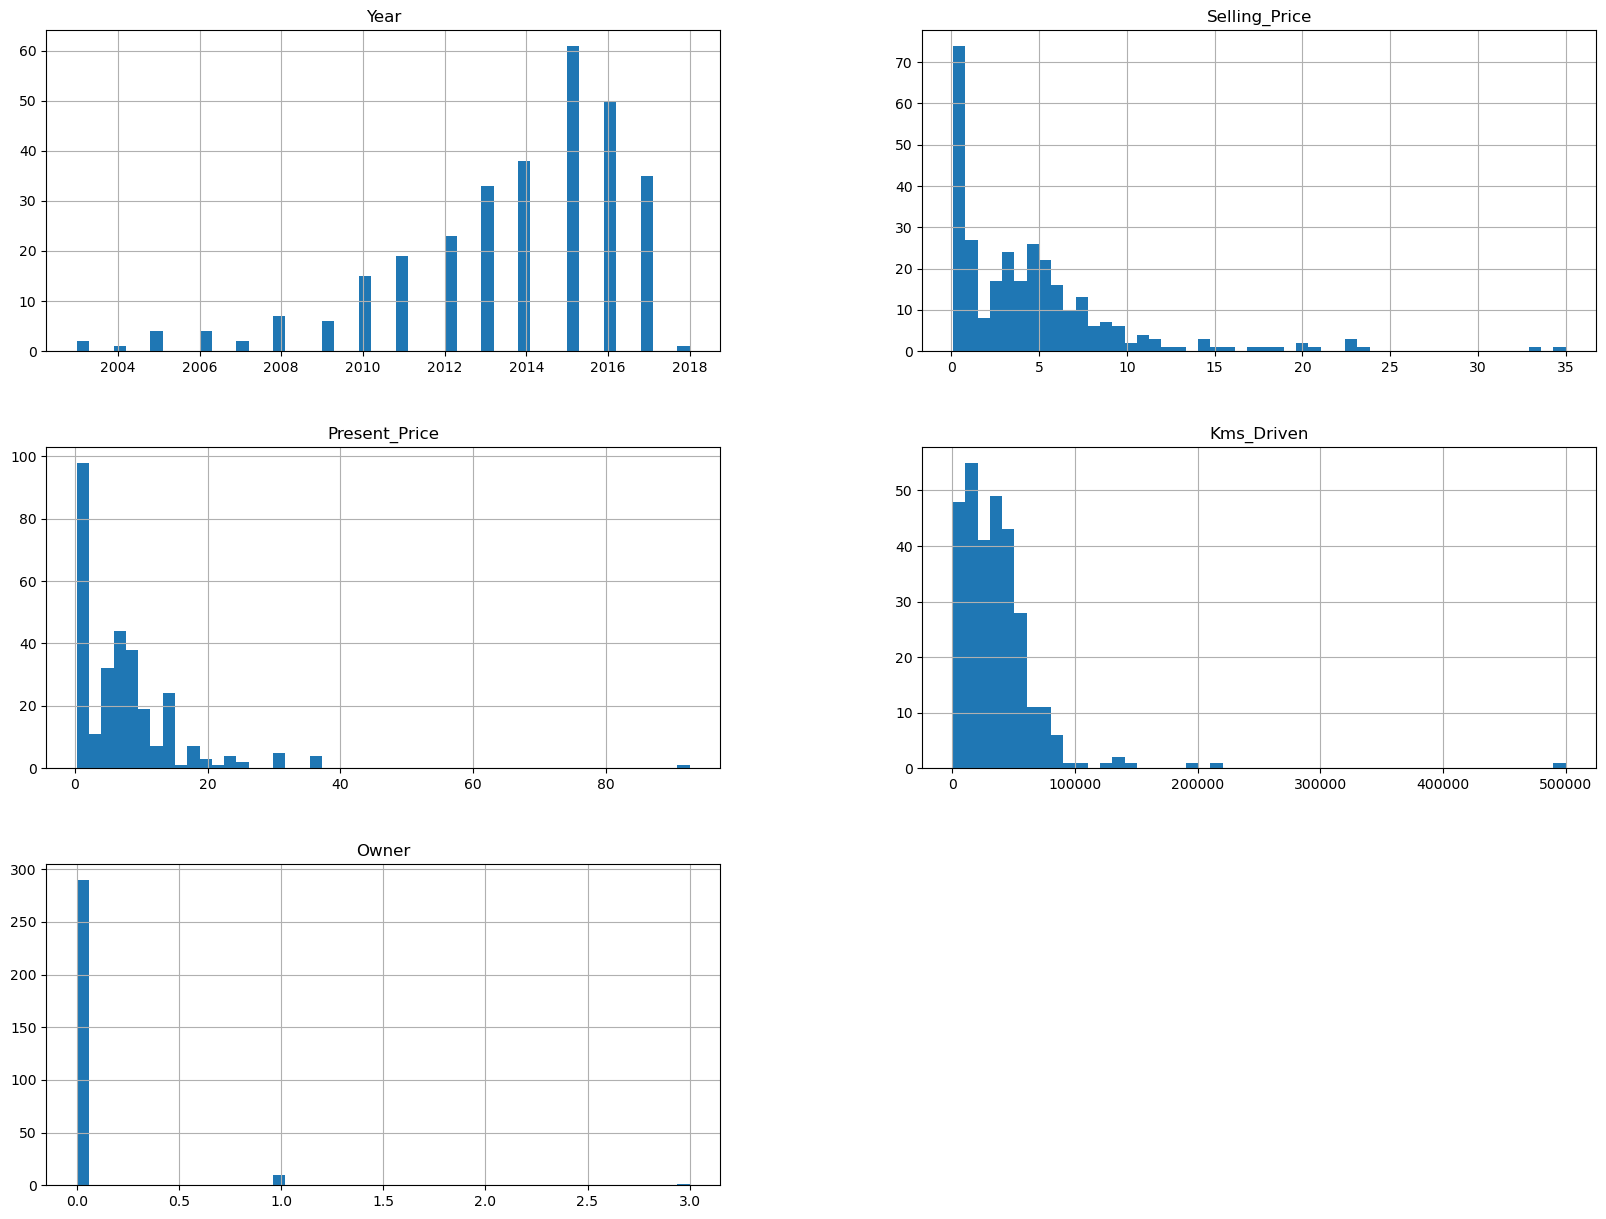

In [5]:
import matplotlib.pyplot as plt

vehicle_full.hist(bins=50, figsize=(20, 15))
plt.show()

In [6]:
vehicle_full.select_dtypes(include="number").corr()["Selling_Price"].sort_values(ascending=False)

Selling_Price    1.000000
Present_Price    0.878983
Year             0.236141
Kms_Driven       0.029187
Owner           -0.088344
Name: Selling_Price, dtype: float64

Time to split the dataset into training and testing sets using stratified sampling on the Present_Price column.

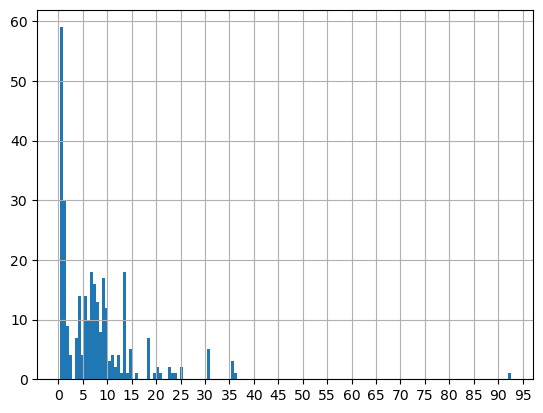

In [7]:
graph = vehicle_full["Present_Price"].hist(bins=150)
graph.set_xticks([0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95])
plt.show()

Present_Price_Category
1    71
2    77
3    87
4    47
5    19
Name: count, dtype: int64


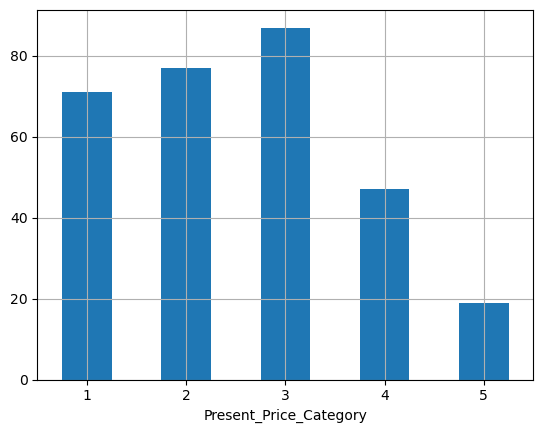

Present_Price_Category
1    0.235880
2    0.255814
3    0.289037
4    0.156146
5    0.063123
Name: count, dtype: float64

In [8]:
import numpy as np

vehicle_full["Present_Price_Category"] = pd.cut(vehicle_full["Present_Price"], bins=[0, 1, 6, 10, 20, np.inf], labels=[1, 2, 3, 4, 5])

category_counts = vehicle_full["Present_Price_Category"].value_counts().sort_index()
print(category_counts)
category_counts.plot.bar(rot=0, grid=True)
plt.show()

vehicle_full["Present_Price_Category"].value_counts().sort_index() / len(vehicle_full)

In [9]:
from sklearn.model_selection import train_test_split

vehicle_train, vehicle_test = train_test_split(vehicle_full, test_size=0.2, stratify=vehicle_full["Present_Price_Category"], random_state=42)

print(len(vehicle_train))
print(len(vehicle_test))

240
61


In [10]:
vehicle_train["Present_Price_Category"].value_counts().sort_index() / len(vehicle_train)

Present_Price_Category
1    0.237500
2    0.254167
3    0.287500
4    0.158333
5    0.062500
Name: count, dtype: float64

## Now lets play with the data for us to know the exact preprocessing steps we will need, so let's make a copy of the dataset

In [11]:
vehicle = vehicle_train.copy()

In [12]:
vehicle.corr(numeric_only=True)["Selling_Price"].sort_values(ascending=False)

Selling_Price    1.000000
Present_Price    0.877608
Year             0.248335
Kms_Driven       0.049263
Owner           -0.099672
Name: Selling_Price, dtype: float64

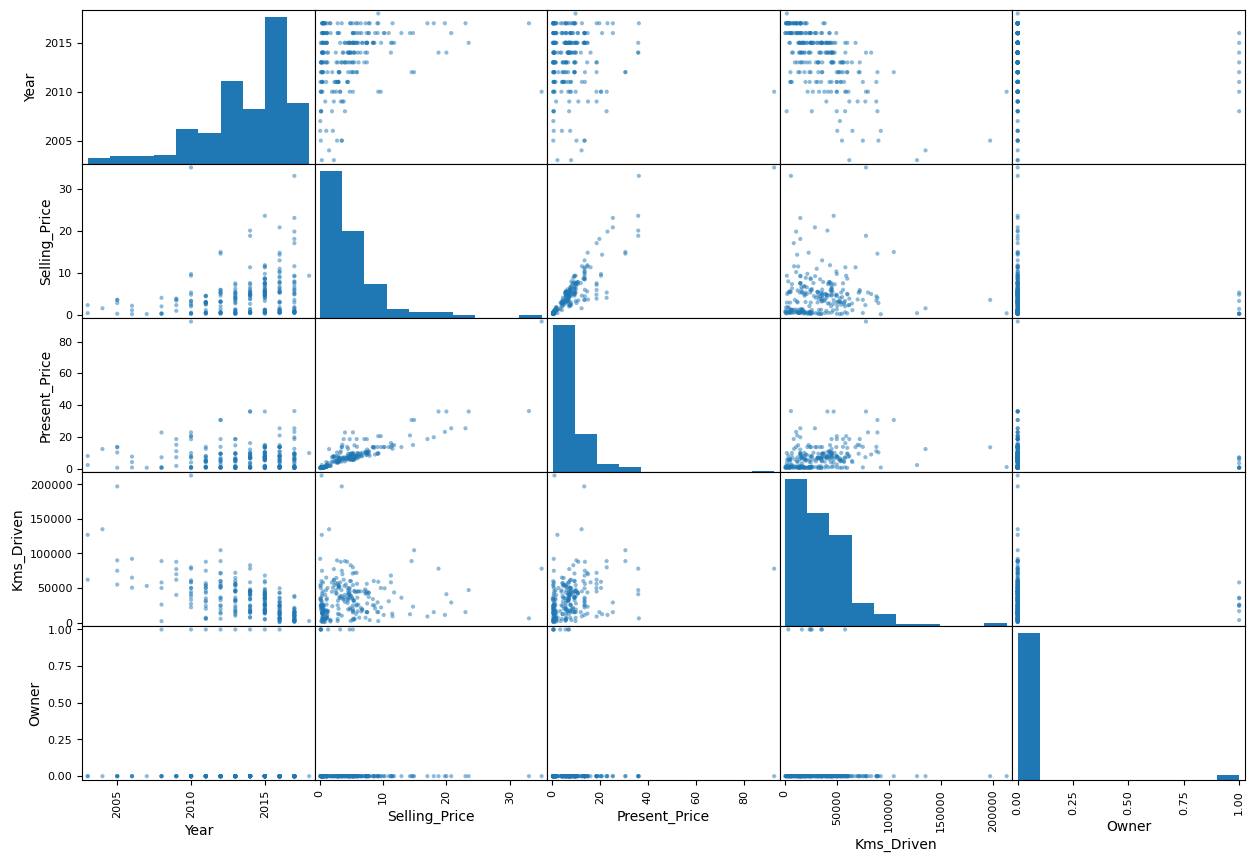

In [13]:
from pandas.plotting import scatter_matrix

scatter_matrix(vehicle.select_dtypes(include="number"), figsize=(15, 10))
plt.show()

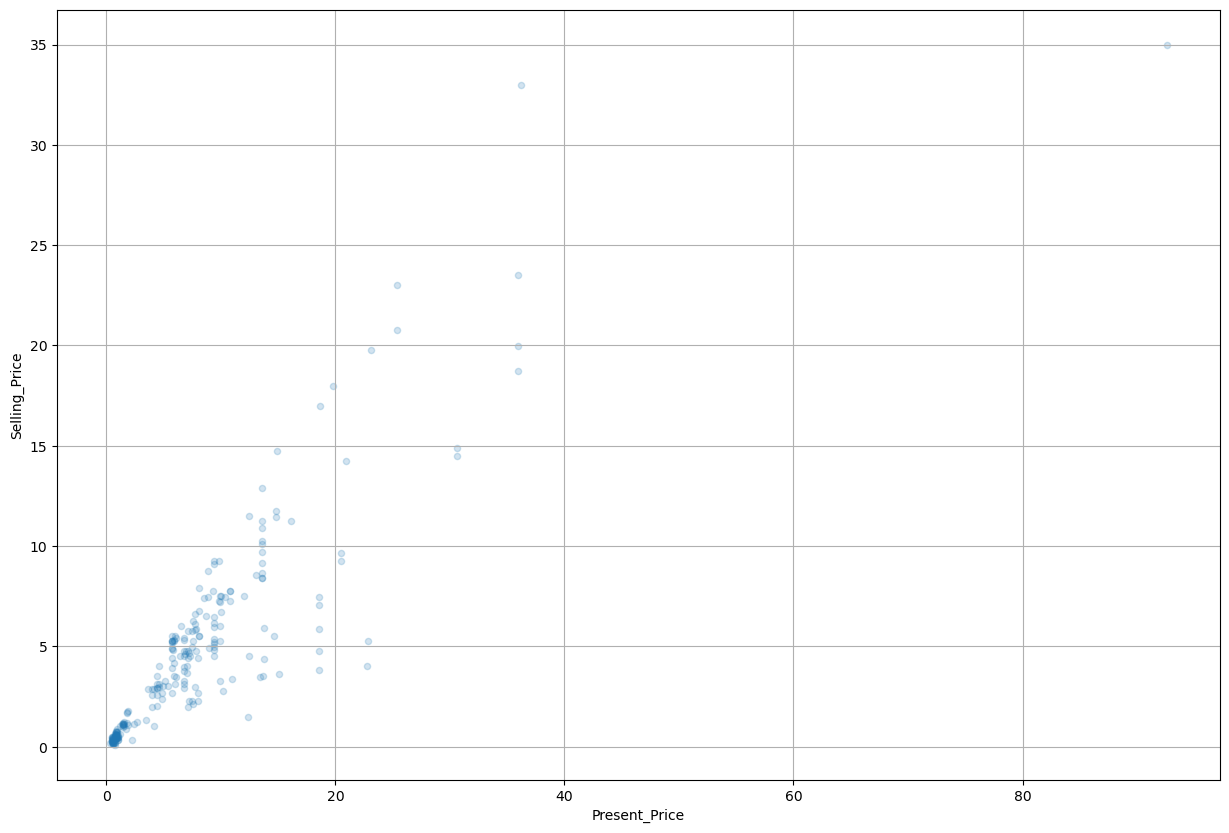

In [14]:
vehicle.plot(kind="scatter", x="Present_Price", y="Selling_Price", alpha=0.2, grid=True, figsize=(15, 10))
plt.show()

Mehn, preprocessing data, and just playing with it to get patterns is one of the biggest part of Machine Learning, not just writing algorithms.
Now, we need more features that are correlated with the Selling_Price column. 

In [15]:
from datetime import datetime

vehicle["Age"] = datetime.now().year - vehicle["Year"]
vehicle["Driving_Intensity"] = vehicle["Kms_Driven"] / vehicle["Age"]
vehicle.drop("Year", axis=1, inplace=True)
vehicle.head()

,Car_Name,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Present_Price_Category,Age,Driving_Intensity
87,corolla altis,5.90,13.74,56000,Petrol,Dealer,Manual,0,4,14,4000.000000
116,Royal Enfield Classic 350,1.10,1.47,33000,Petrol,Individual,Manual,0,2,13,2538.461538
27,swift,6.00,6.49,16200,Petrol,Individual,Manual,0,3,9,1800.000000
44,omni,1.25,2.69,50000,Petrol,Dealer,Manual,0,2,14,3571.428571
229,i20,3.10,6.79,52132,Diesel,Dealer,Manual,0,3,14,3723.714286


In [16]:
vehicle.corr(numeric_only=True)["Selling_Price"].sort_values(ascending=False)

Selling_Price        1.000000
Present_Price        0.877608
Driving_Intensity    0.159907
Kms_Driven           0.049263
Owner               -0.099672
Age                 -0.248335
Name: Selling_Price, dtype: float64

Now we need to create a preprocessing pipeline. This preprocessing pipeline will contain an imputer, a one-hot encoder, standardscaler, make the numeric values normally distributed because they are skewed, and that's all. Meanwhile, let's test these one by one before we put everything together.

In [17]:
from sklearn.impute import SimpleImputer

imputer_num = SimpleImputer(strategy="mean")
imputer_cat = SimpleImputer(strategy="most_frequent")

vehicle_num = vehicle.select_dtypes(include=np.number)
vehicle_cat = vehicle.select_dtypes(include=object)

vehicle_num_imputed = pd.DataFrame(imputer_num.fit_transform(vehicle_num), columns=vehicle_num.columns, index=vehicle_num.index)
vehicle_cat_imputed = pd.DataFrame(imputer_cat.fit_transform(vehicle_cat), columns=vehicle_cat.columns, index=vehicle_cat.index)

print(vehicle_num_imputed.head())
print(vehicle_cat_imputed.head())

print(imputer_num.statistics_)
print(imputer_cat.statistics_)

     Selling_Price  Present_Price  Kms_Driven  Owner   Age  Driving_Intensity
87            5.90          13.74     56000.0    0.0  14.0        4000.000000
116           1.10           1.47     33000.0    0.0  13.0        2538.461538
27            6.00           6.49     16200.0    0.0   9.0        1800.000000
44            1.25           2.69     50000.0    0.0  14.0        3571.428571
229           3.10           6.79     52132.0    0.0  14.0        3723.714286
                      Car_Name Fuel_Type Seller_Type Transmission
87               corolla altis    Petrol      Dealer       Manual
116  Royal Enfield Classic 350    Petrol  Individual       Manual
27                       swift    Petrol  Individual       Manual
44                        omni    Petrol      Dealer       Manual
229                        i20    Diesel      Dealer       Manual
[4.68429167e+00 7.69162500e+00 3.51576333e+04 3.33333333e-02
 1.24666667e+01 2.65539703e+03]
['city' 'Petrol' 'Dealer' 'Manual']


In [18]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

vehicle_encoded = encoder.fit_transform(vehicle_cat)
vehicle_encoded

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 960 stored elements and shape (240, 94)>

In [19]:
vehicle_encoded.toarray()

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 1., 0., 1.],
       [0., 0., 0., ..., 1., 0., 1.],
       ...,
       [0., 0., 0., ..., 1., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]])

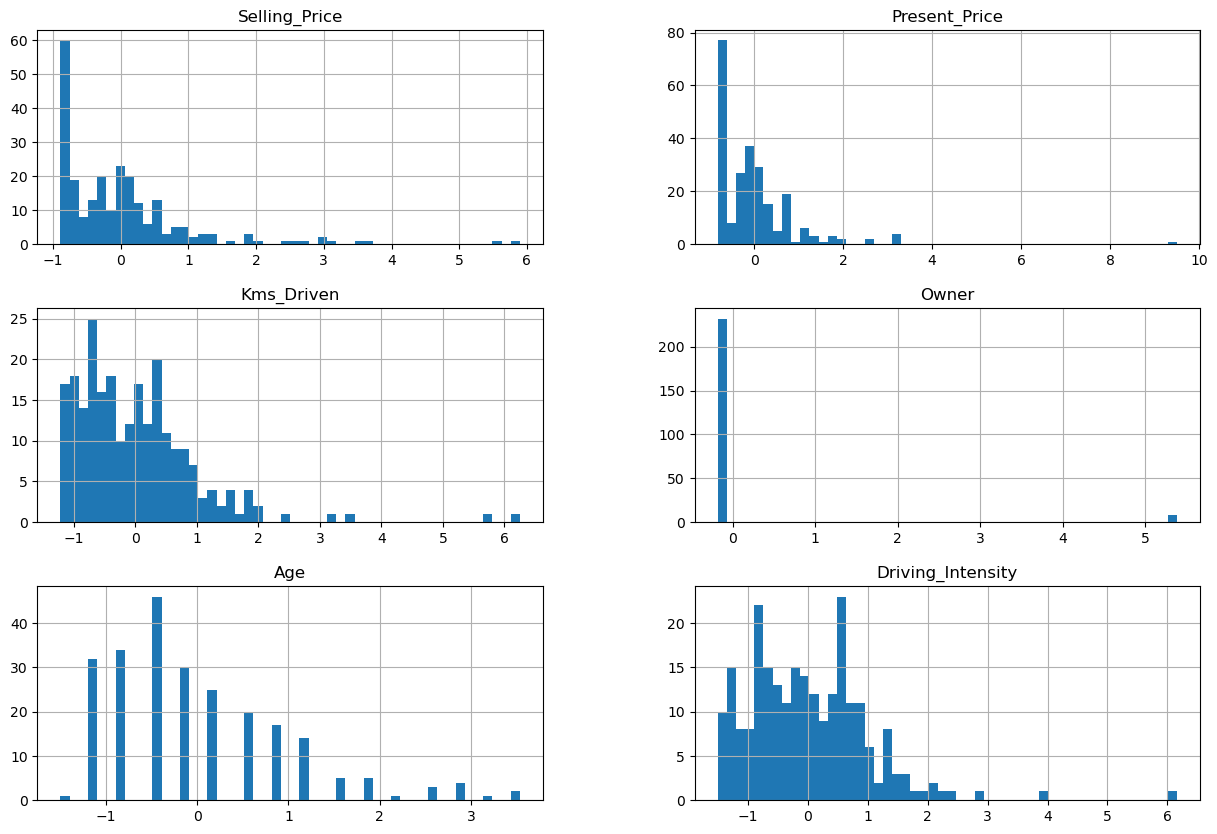

In [20]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

vehicle_num_standardized = pd.DataFrame(scaler.fit_transform(vehicle_num), columns=vehicle_num.columns, index=vehicle_num.index)

vehicle_num_standardized.hist(bins=50, figsize=(15,10))
plt.show()

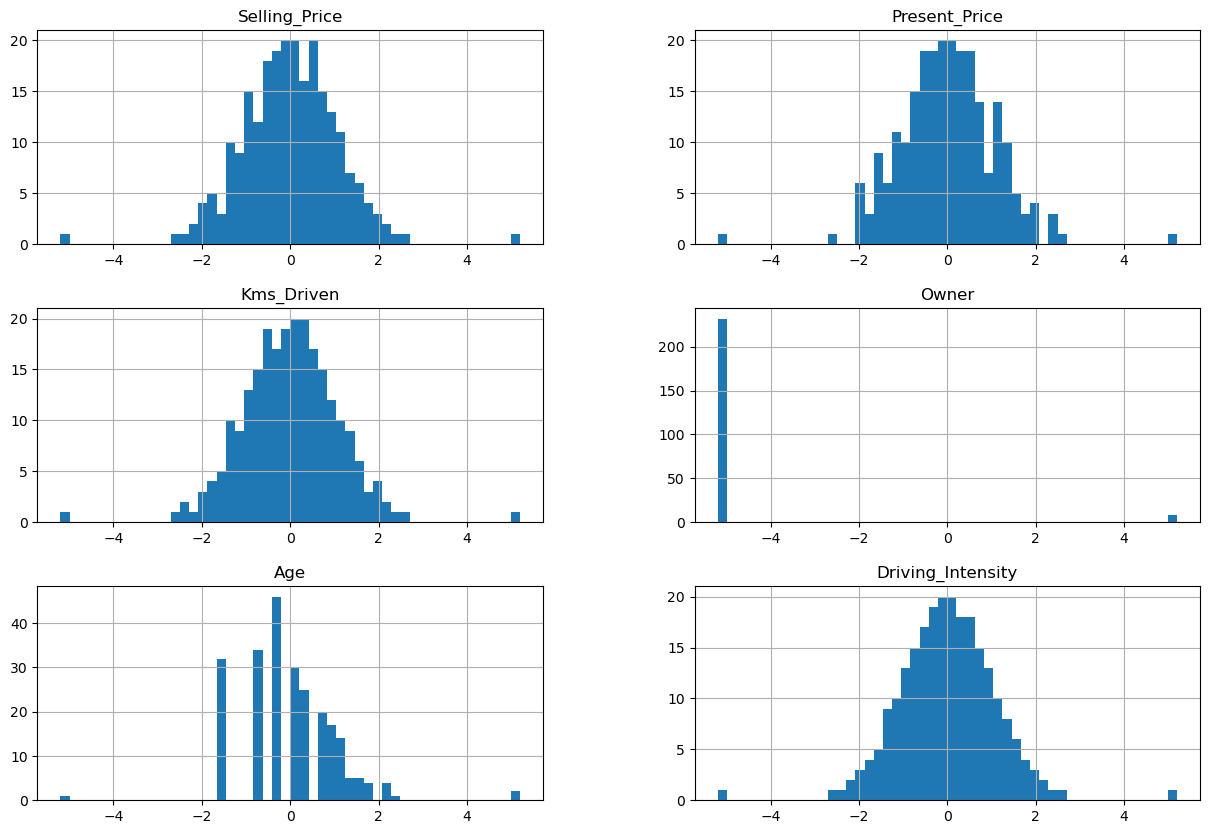

In [21]:
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution="normal", random_state=42, n_quantiles=vehicle_num_standardized.shape[0])


vehicle_num_log = pd.DataFrame(qt.fit_transform(vehicle_num_standardized), columns=vehicle_num_standardized.columns, 
                               index=vehicle_num_standardized.index)
vehicle_num_log.hist(bins=50, figsize=(15,10))
plt.show()

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer


category_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)
num_pipeline = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    QuantileTransformer(output_distribution="normal", random_state=42)
)
target_pipeline = make_pipeline(
    SimpleImputer(strategy="mean", add_indicator=True),
    StandardScaler(),
    QuantileTransformer(output_distribution="normal", random_state=42)
)

def calculate_age(X):
    return datetime.now().year - X[:, [0]]
def calculate_driving_intensity(X):
    return X[:, [0]] / (datetime.now().year - X[:, [1]])
def age_name(function_transformer, feature_names_in):
    return ["Age"]
def ratio_name(function_transformer, feature_names_in):
    return ["Driving_Intensity"]
    
age_pipeline = make_pipeline(
    SimpleImputer(strategy="mean"),
    FunctionTransformer(calculate_age, feature_names_out=age_name),
    StandardScaler(),
    QuantileTransformer(output_distribution="normal", random_state=42)
)
ratio_pipeline = make_pipeline(
    SimpleImputer(strategy="mean"),
    FunctionTransformer(calculate_driving_intensity, feature_names_out=ratio_name),
    StandardScaler(),
    QuantileTransformer(output_distribution="normal", random_state=42)
)

preprocessing = ColumnTransformer([
    ("age", age_pipeline, ["Year"]),
    ("ratio", ratio_pipeline, ["Kms_Driven", "Year"]),
    ("numeric", num_pipeline, ["Present_Price", "Kms_Driven", "Owner"]),
    ("category", category_pipeline, ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"])
])
# new_data = preprocessing.fit_transform(vehicle_predictors, vehicle_target)
# print(new_data.toarray())
# preprocessing.get_feature_names_out()
# vehicle_num_log = pd.DataFrame(new_data.toarray()[:, 0:5], columns=preprocessing.get_feature_names_out()[0:5])
# vehicle_num_log.hist(bins=50, figsize=(15,10))
# plt.show()


In [23]:
vehicle_predictors = vehicle_train.drop("Selling_Price", axis=1)
vehicle_target = vehicle_train["Selling_Price"]

In [24]:
import warnings
warnings.filterwarnings(
    "ignore", 
    message="n_quantiles .* is greater than the total number of samples", 
    category=UserWarning
)

In [25]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = TransformedTargetRegressor(LinearRegression(), transformer=target_pipeline)

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", model)
])

full_pipeline.fit(vehicle_predictors, vehicle_target)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('age',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function age_name at 0x000001B38D6345E0>,
                                                                                       func=<function calculate_age at 0x000001B38C467CE0>)),
                                                                  ('standardscaler',
                                                                   StandardScaler()),
                                                                  ('quantiletransformer',
                                                                   QuantileTransforme...
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Car_Name', 'Fuel_Type',
                                                   'Seller_Type',
                                                   'Transmission'])])),
                ('model',
                 TransformedTargetRegressor(regressor=LinearRegression(),
                                            transformer=Pipeline(steps=[('simpleimputer',
                                                                         SimpleImputer(add_indicator=True)),
                                                                        ('standardscaler',
                                                                         StandardScaler()),
                                                                        ('quantiletransformer',
                                                                         QuantileTransformer(output_distribution='normal',
                                                                                             random_state=42))])))])

In [26]:
vehicle_predictions = full_pipeline.predict(vehicle_predictors)
vehicle_predictions[:10]

array([5.37165944, 0.75      , 6.        , 1.25      , 3.25      ,
       4.7458218 , 5.26865649, 5.25      , 6.01956326, 0.17999986])

In [27]:
vehicle_target[0:10].values

array([5.9 , 1.1 , 6.  , 1.25, 3.1 , 3.6 , 5.5 , 4.5 , 6.6 , 0.18])

Hmm, it looks so close to the actual values, but don't get excited too fast because the model might be overfitting the training set.

In [28]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(vehicle_target, vehicle_predictions)
rmse

0.8248467064628104

Hmm, let's use cross validation.

In [29]:
from sklearn.model_selection import cross_val_score

cross_val_rmse = -cross_val_score(full_pipeline, vehicle_predictors, vehicle_target, scoring="neg_root_mean_squared_error", cv=10)

In [30]:
pd.Series(cross_val_rmse).describe()

count    10.000000
mean      1.251098
std       0.358198
min       0.893641
25%       1.008724
50%       1.113132
75%       1.402205
max       1.885728
dtype: float64

Woah, the mean is about 1.25 with a standard deviation of 0.36. The LinearRegression model seems to do quite well, but let's try other models to see if we can get a better model.

In [31]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score

model = TransformedTargetRegressor(DecisionTreeRegressor(), transformer=target_pipeline)

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", model)
])

full_pipeline.fit(vehicle_predictors, vehicle_target)

vehicle_predictions = full_pipeline.predict(vehicle_predictors)
print(vehicle_predictions[:10])
print(vehicle_target[0:10].values)


rmse = root_mean_squared_error(vehicle_target, vehicle_predictions)
print(rmse)


cross_val_rmse = -cross_val_score(full_pipeline, vehicle_predictors, vehicle_target, scoring="neg_root_mean_squared_error", cv=10)
print(pd.Series(cross_val_rmse).describe())

[5.9  1.1  6.   1.25 3.1  3.6  5.5  4.5  6.6  0.18]
[5.9  1.1  6.   1.25 3.1  3.6  5.5  4.5  6.6  0.18]
2.6310927879785954e-15
count    10.000000
mean      1.242582
std       0.464486
min       0.579562
25%       1.067374
50%       1.196077
75%       1.463430
max       2.219013
dtype: float64



The Decision Tree Regressor did better than the Linear Regressor model with mean of 1.19 and standard deviation of 0.47.

Let's find the best parameters.

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

parameter_distribution = {
    'model__regressor__min_samples_split': randint(2, 20),
    
    'model__regressor__min_samples_leaf': randint(1, 10),
}

random_search = RandomizedSearchCV(
    full_pipeline, param_distributions=parameter_distribution, n_iter=100, cv=5, scoring="neg_root_mean_squared_error", random_state=42
)

random_search.fit(vehicle_predictors, vehicle_target)
print(random_search.best_params_)
print(-random_search.best_score_)
rs_df = pd.DataFrame(random_search.cv_results_)
rs_df.sort_values(by="mean_test_score", ascending=False, inplace=True)
rs_df.head()

{'model__regressor__min_samples_leaf': 2, 'model__regressor__min_samples_split': 6}
1.490828885356167


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__regressor__min_samples_leaf,param_model__regressor__min_samples_split,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
79,0.049163,0.006411,0.022364,0.001100,2,6,"{'model__regressor__min_samples_leaf': 2, 'mod...",-1.020010,-3.020335,-1.507927,-1.127951,-0.777921,-1.490829,0.800159,1
63,0.059996,0.003060,0.027942,0.005454,1,2,"{'model__regressor__min_samples_leaf': 1, 'mod...",-1.810324,-2.122519,-2.033269,-1.049794,-0.699007,-1.542982,0.566259,2
78,0.047889,0.001694,0.023339,0.002460,1,3,"{'model__regressor__min_samples_leaf': 1, 'mod...",-1.797401,-2.099343,-2.036029,-1.209905,-0.753672,-1.579270,0.518600,3
80,0.053604,0.006393,0.021765,0.001107,1,2,"{'model__regressor__min_samples_leaf': 1, 'mod...",-2.203385,-2.086457,-2.032501,-1.090756,-0.620338,-1.606687,0.633501,4
46,0.059526,0.008161,0.028132,0.007053,2,2,"{'model__regressor__min_samples_leaf': 2, 'mod...",-1.746671,-2.958883,-1.756931,-0.963677,-0.789350,-1.643103,0.767525,5


In [33]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score

model = TransformedTargetRegressor(RandomForestRegressor(n_jobs=-1), transformer=target_pipeline)

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", model)
])

full_pipeline.fit(vehicle_predictors, vehicle_target)

vehicle_predictions = full_pipeline.predict(vehicle_predictors)
print(vehicle_predictions[:10])
print(vehicle_target[0:10].values)


rmse = root_mean_squared_error(vehicle_target, vehicle_predictions)
print(rmse)


cross_val_rmse = -cross_val_score(full_pipeline, vehicle_predictors, vehicle_target, scoring="neg_root_mean_squared_error", cv=10)
print(pd.Series(cross_val_rmse).describe())

[5.89746065 1.1        5.75       1.17979356 3.27122542 4.
 5.38926139 4.75       6.04971829 0.2       ]
[5.9  1.1  6.   1.25 3.1  3.6  5.5  4.5  6.6  0.18]
0.6236543339628597
count    10.000000
mean      1.101490
std       0.486185
min       0.499426
25%       0.861965
50%       1.019756
75%       1.160123
max       2.350484
dtype: float64


Hmm, Random Forest Regressor did even better than the first two model, but it still overfitted the training set.

Let's find the best parameters.

In [34]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

parameter_distribution = {
    'model__regressor__n_estimators': randint(100, 500),
    'model__regressor__max_depth': [3, 5, 7, 10, None], # Forces the trees to stay shallow
    'model__regressor__max_features': ['sqrt', 'log2', 1.0], # Prevents relying on the same dominant feature
    'model__regressor__min_samples_split': randint(2, 15),
    'model__regressor__min_samples_leaf': randint(1, 10)
}

random_search = RandomizedSearchCV(
    full_pipeline, param_distributions=parameter_distribution, n_iter=100, cv=5, scoring="neg_root_mean_squared_error", random_state=42
)

random_search.fit(vehicle_predictors, vehicle_target)
print(random_search.best_params_)
print(-random_search.best_score_)
rs_df = pd.DataFrame(random_search.cv_results_)
rs_df.sort_values(by="mean_test_score", ascending=False, inplace=True)
rs_df.head()

{'model__regressor__max_depth': 7, 'model__regressor__max_features': 1.0, 'model__regressor__min_samples_leaf': 1, 'model__regressor__min_samples_split': 7, 'model__regressor__n_estimators': 379}
1.2727793856541465


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__regressor__max_depth,param_model__regressor__max_features,param_model__regressor__min_samples_leaf,param_model__regressor__min_samples_split,param_model__regressor__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
42,1.535361,0.049748,0.257302,0.012902,7,1.0,1,7,379,"{'model__regressor__max_depth': 7, 'model__reg...",-2.031180,-1.243846,-1.024231,-1.060401,-1.004238,-1.272779,0.388588,1
93,1.074593,0.056351,0.211144,0.031601,5,1.0,1,2,278,"{'model__regressor__max_depth': 5, 'model__reg...",-2.060781,-1.214683,-1.386322,-1.235871,-0.976532,-1.374838,0.367222,2
20,1.326805,0.030380,0.234357,0.020527,7,1.0,1,12,360,"{'model__regressor__max_depth': 7, 'model__reg...",-2.084229,-1.485351,-1.277473,-1.127581,-1.177509,-1.430429,0.349157,3
96,1.269108,0.045629,0.233156,0.016096,7,1.0,1,11,363,"{'model__regressor__max_depth': 7, 'model__reg...",-2.085027,-1.604662,-1.254570,-1.156247,-1.135811,-1.447263,0.360650,4
69,1.292726,0.042260,0.210830,0.008949,5,1.0,2,11,372,"{'model__regressor__max_depth': 5, 'model__reg...",-1.744146,-2.393069,-1.343449,-1.186275,-1.190312,-1.571450,0.458365,5


In [35]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score

model = TransformedTargetRegressor(SVR(), transformer=target_pipeline)

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", model)
])

full_pipeline.fit(vehicle_predictors, vehicle_target)

vehicle_predictions = full_pipeline.predict(vehicle_predictors)
print(vehicle_predictions[:10])
print(vehicle_target[0:10].values)


rmse = root_mean_squared_error(vehicle_target, vehicle_predictions)
print(rmse)


cross_val_rmse = -cross_val_score(full_pipeline, vehicle_predictors, vehicle_target, scoring="neg_root_mean_squared_error", cv=10)
print(pd.Series(cross_val_rmse).describe())

[5.5        0.65       4.5        1.26449543 3.7798461  4.75
 4.7581408  5.25       5.8488074  0.2       ]
[5.9  1.1  6.   1.25 3.1  3.6  5.5  4.5  6.6  0.18]
1.239083043847565
count    10.000000
mean      1.525082
std       1.101844
min       0.692393
25%       0.878260
50%       1.189439
75%       1.708573
max       4.352319
dtype: float64


Let's run some search to look for the best parameters.

In [36]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

parameter_distribution = {
    "model__regressor__kernel": ["linear", "rbf"],
    "model__regressor__C": loguniform(0.1, 1000),
    "model__regressor__gamma": ["scale", "auto"]
}

random_search = RandomizedSearchCV(
    full_pipeline, param_distributions=parameter_distribution, n_iter=20, cv=5, scoring="neg_root_mean_squared_error", random_state=42
)

random_search.fit(vehicle_predictors, vehicle_target)
print(random_search.best_params_)
print(-random_search.best_score_)
rs_df = pd.DataFrame(random_search.cv_results_)
rs_df.sort_values(by="mean_test_score", ascending=False, inplace=True)
rs_df.head()

{'model__regressor__C': np.float64(28.016351587162582), 'model__regressor__gamma': 'auto', 'model__regressor__kernel': 'rbf'}
0.9622505180829201


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__regressor__C,param_model__regressor__gamma,param_model__regressor__kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
10,0.109379,0.029618,0.043123,0.008085,28.016352,auto,rbf,"{'model__regressor__C': 28.016351587162582, 'm...",-1.138280,-1.093143,-0.906611,-0.752733,-0.920485,-0.962251,0.139181,1
6,0.092732,0.005005,0.037388,0.005326,213.683291,auto,rbf,"{'model__regressor__C': 213.6832907235874, 'mo...",-1.209234,-1.691664,-0.979599,-0.744692,-0.861833,-1.097404,0.334493,2
16,0.077570,0.005096,0.035938,0.001732,0.182057,auto,linear,"{'model__regressor__C': 0.18205657658407254, '...",-1.221386,-1.344808,-0.941651,-1.172487,-1.242693,-1.184605,0.133840,3
3,0.082641,0.007871,0.034791,0.001631,0.170740,auto,linear,"{'model__regressor__C': 0.17073967431528117, '...",-1.223760,-1.344072,-0.950013,-1.172829,-1.240786,-1.186292,0.130596,4
9,0.194380,0.060446,0.036381,0.006500,5.342937,scale,linear,"{'model__regressor__C': 5.342937261279771, 'mo...",-1.157649,-1.413208,-1.103525,-1.094083,-1.181549,-1.190002,0.116291,5


Seems like we have a winner. Our winner is ... Support Vector Machine Regression with a mean of 0.96 and a standard deviation of 0.14

In [37]:
final_model = random_search.best_estimator_
final_model

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('age',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer()),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function age_name at 0x000001B38D6345E0>,
                                                                                       func=<function calculate_age at 0x000001B38C467CE0>)),
                                                                  ('standardscaler',
                                                                   StandardScaler()),
                                                                  ('quantiletransformer',
                                                                   QuantileTransforme...
                                                  ['Car_Name', 'Fuel_Type',
                                                   'Seller_Type',
                                                   'Transmission'])])),
                ('model',
                 TransformedTargetRegressor(regressor=SVR(C=np.float64(28.016351587162582),
                                                          gamma='auto'),
                                            transformer=Pipeline(steps=[('simpleimputer',
                                                                         SimpleImputer(add_indicator=True)),
                                                                        ('standardscaler',
                                                                         StandardScaler()),
                                                                        ('quantiletransformer',
                                                                         QuantileTransformer(output_distribution='normal',
                                                                                             random_state=42))])))])

Time to test our best model on our test set.

In [38]:
X_test = vehicle_test.drop("Selling_Price", axis=1)
y_test = vehicle_test["Selling_Price"].copy()

In [39]:
final_predictions = final_model.predict(X_test)
final_rmse = root_mean_squared_error(final_predictions, y_test)
final_rmse

1.1219528171181967

In [40]:
from scipy import stats

def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))

confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
boot_result = stats.bootstrap([squared_errors], rmse, confidence_level=confidence, random_state=42)
rmse_lower, rmse_higher = boot_result.confidence_interval

print(rmse_lower, rmse_higher)

0.7970452502330213 1.641077780082522


We are 95% confident that our RMSE by our SVM model lies between 0.7970 and 1.6411

## Time to save our model!

In [41]:
import joblib

joblib.dump(final_model, "used_vehicle_model.pkl")

['used_vehicle_model.pkl']

# Try It Out!

For non-programmers you can test this model and get the selling price for your used car by editing the values in the `custom_car` variable. Follow the steps below: \
1. First enter your car name in the `Car_Name` section by changing `swift` to the name of your car.
2. Enter the year the first buyer bought the car in the `Year` section by changing `2017` to your preferred value.
3. Enter the present price of the car in the `Present_Price` section by changing `7.50` to your preferred value.
4. Enter the distance that the car has driven so far in kilometers in the `Kms_Driven` section by changing `42000` to your preferred value.
5. Enter the fuel type of the car in the `Fuel_Type` section by changing `Petrol` to your preferred value.
6. Enter the type of seller of the car in the `Seller_Type` section by changing `Dealer` to your preferred value.
7. Enter the transmission of the car in the `Transmission` section by changing `Manual` to your preferred value.
8. Enter the number of owners the car has previously had in the `Owner` section by changing `0` to your preferred value.\

Thank you!

In [43]:
import joblib
import pandas as pd
from datetime import datetime

def calculate_age(X):
    return datetime.now().year - X[:, [0]]
def calculate_driving_intensity(X):
    return X[:, [0]] / (datetime.now().year - X[:, [1]])
def age_name(function_transformer, feature_names_in):
    return ["Age"]
def ratio_name(function_transformer, feature_names_in):
    return ["Driving_Intensity"]

# Edit the values here.
custom_car = {
    "Car_Name": ["swift"], # This column should be filled with the name of the car.
    "Year": [2017], # This column should be filled with the year in which the car was bought.
    "Present_Price": [7.50], # This is the current ex-showroom price of the car in Lakhs.
    "Kms_Driven": [42000], # This is the distance completed by the car in km.
    "Fuel_Type": ["Petrol"], # Fuel type of the car (Petrol, Diesel, or Other).
    "Seller_Type": ["Dealer"], # Defines whether the seller is a Dealer or an Individual.
    "Transmission": ["Manual"], # Defines whether the car is Manual or Automatic.
    "Owner": [0] # Defines the number of owners the car has previously had.
}

custom_data = pd.DataFrame(custom_car)

final_model_reloaded = joblib.load("used_vehicle_model.pkl")

predictions = final_model_reloaded.predict(custom_data)
print(f"The prediction for your used car's Selling Price is {predictions[0]} Lakhs.")


The prediction for your used car's Selling Price is 7.45 Lakhs.
